# 5. LightGBM con Learning Rate Bajo y Semillas — Predicting Airline Satisfaction

El LightGBM de `4_lightgbm.ipynb` llegó a **CV AUC = 0,95898**, +0,00040 sobre XGBoost en 5 de 5 folds,
pero con `learning_rate=0.05` el early stopping cortaba en ~200 árboles. Eso deja dos fuentes de
ganancia baratas, que no requieren features nuevas:

1. **Learning rate más bajo** (`0.02`): cada árbol corrige menos, hacen falta más árboles y el ajuste
   final es más fino.
2. **Promedio de semillas**: `subsample` y `colsample_bytree` hacen que cada semilla vea filas y
   columnas distintas. Promediar varias reduce la varianza de la predicción sin cambiar el sesgo.

El notebook separa las dos: la semilla 1 sola mide el efecto del learning rate, y el promedio de
las 3 mide lo que suma promediar.

Antes de este notebook se probó sumar el **dataset original** (129.880 filas reales) al
entrenamiento. En un fold dio −0,00008 sumado tal cual, +0,00012 con una columna de origen y
−0,00046 con peso doble. Es ruido o peor: las distribuciones no coinciden (en el sintético el 91 % de
las demoras son 0, en el original el 57 %), así que quedó descartado.

- **Mismos folds que los notebooks 3 y 4**, así que la comparación con ambos es **pareada**.
- **Mismos parámetros que el notebook 4** (`num_leaves=255`), salvo el learning rate y la semilla.

> **Tiempo de ejecución: ~27 minutos** en CPU. Referencia medida en una prueba: **~100 s por modelo** (un fold, una semilla: early stopping en 469 árboles, AUC 0,95930 contra 0,95927 del notebook 4), y son 15 modelos.

**Métrica:** ROC AUC — **Dataset:** Playground Series S6E10

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import time
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 6)
plt.rcParams["figure.dpi"] = 100

SEED    = 42
N_FOLDS = 5
SEMILLAS = [42, 7, 2026]

## 1. Carga y Preprocesamiento

In [2]:
train = pd.read_csv("../data/train.csv")
test  = pd.read_csv("../data/test.csv")

TARGET = "satisfaction"

crudas_num = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
encuesta = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
            "Gate location", "Food and drink", "Online boarding", "Seat comfort",
            "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
            "Checkin service", "Cleanliness"]
crudas_cat = ["Gender", "Customer Type", "Type of Travel", "Class"]
features   = crudas_num + encuesta + crudas_cat

for col in crudas_cat:
    dtype = pd.CategoricalDtype(categories=sorted(set(train[col]) | set(test[col])), ordered=False)
    train[col] = train[col].astype(dtype)
    test[col]  = test[col].astype(dtype)

y = train[TARGET].astype(int).values

skf   = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(train[features], y))

# OOF de los modelos anteriores, para las comparaciones pareadas y la mezcla
oof_xgb  = np.load("../models/3_xgboost_oof.npy")
test_xgb = np.load("../models/3_xgboost_test.npy")
oof_nb4  = np.load("../models/4_lightgbm_oof.npy")


def aucs_por_fold(pred):
    return np.array([roc_auc_score(y[va], pred[va]) for _, va in folds])


aucs_xgb = aucs_por_fold(oof_xgb)
aucs_nb4 = aucs_por_fold(oof_nb4)

print(f"Train: {train.shape[0]:,} filas | Test: {test.shape[0]:,} filas | Features: {len(features)}")
print(f"XGBoost  (notebook 3) por fold: {np.round(aucs_xgb, 5)}  media {aucs_xgb.mean():.5f}")
print(f"LightGBM (notebook 4) por fold: {np.round(aucs_nb4, 5)}  media {aucs_nb4.mean():.5f}")

Train: 699,635 filas | Test: 299,844 filas | Features: 21
XGBoost  (notebook 3) por fold: [0.95875 0.95742 0.95941 0.95845 0.95886]  media 0.95858
LightGBM (notebook 4) por fold: [0.95927 0.95789 0.95961 0.95907 0.95907]  media 0.95898


## 2. Validación Cross-Validation

Para cada fold se entrenan 3 modelos con distinta semilla y se guarda el OOF de cada uno. La
predicción del fold es el promedio de las 3 probabilidades, y la de test, el promedio de los 15
modelos.

> Esta es la celda pesada: ~27 minutos.

In [3]:
PARAMS = dict(
    objective="binary",
    n_estimators=10000,         # techo; el early stopping corta mucho antes
    learning_rate=0.02,
    num_leaves=255,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=1.0,
    n_jobs=-1,
    verbose=-1,
)

oof_semilla = np.zeros((len(SEMILLAS), len(train)), dtype=np.float32)
test_sum    = np.zeros(len(test), dtype=np.float32)
iters, modelos = [], []

print(f"{'='*72}")
print(f"CROSS-VALIDATION - LightGBM lr={PARAMS['learning_rate']}, {len(SEMILLAS)} semillas")
print(f"{'='*72}")
t0 = time.time()
for fold, (tr_idx, va_idx) in enumerate(folds, 1):
    linea = []
    for s, semilla in enumerate(SEMILLAS):
        m = lgb.LGBMClassifier(**PARAMS, random_state=semilla)
        m.fit(train[features].iloc[tr_idx], y[tr_idx],
              eval_set=[(train[features].iloc[va_idx], y[va_idx])], eval_metric="auc",
              callbacks=[lgb.early_stopping(300, verbose=False)])
        oof_semilla[s, va_idx] = m.predict_proba(train[features].iloc[va_idx])[:, 1]
        test_sum += m.predict_proba(test[features])[:, 1]
        iters.append(m.best_iteration_)
        modelos.append(m)
        linea.append(f"{roc_auc_score(y[va_idx], oof_semilla[s, va_idx]):.5f}")
    prom = roc_auc_score(y[va_idx], oof_semilla[:, va_idx].mean(axis=0))
    print(f"  Fold {fold}: semillas {' / '.join(linea)}  ->  promedio {prom:.5f}"
          f"   ({(time.time() - t0) / 60:.1f} min)", flush=True)

oof        = oof_semilla.mean(axis=0)
proba_test = test_sum / (N_FOLDS * len(SEMILLAS))
aucs       = aucs_por_fold(oof)
aucs_s1    = aucs_por_fold(oof_semilla[0])
cv_mean    = aucs.mean()

print(f"{'='*72}")
print(f"  Semilla {SEMILLAS[0]} sola:     {aucs_s1.mean():.5f} +/- {aucs_s1.std():.5f}")
print(f"  Promedio de semillas: {cv_mean:.5f} +/- {aucs.std():.5f}")
print(f"  AUC out-of-fold:      {roc_auc_score(y, oof):.5f}")
print(f"  Arboles usados (media): {np.mean(iters):.0f}")
print(f"{'='*72}")

CROSS-VALIDATION - LightGBM lr=0.02, 3 semillas
  Fold 1: semillas 0.95940 / 0.95942 / 0.95936  ->  promedio 0.95949   (12.6 min)
  Fold 2: semillas 0.95802 / 0.95785 / 0.95806  ->  promedio 0.95807   (23.4 min)
  Fold 3: semillas 0.95980 / 0.95971 / 0.95981  ->  promedio 0.95989   (34.6 min)
  Fold 4: semillas 0.95914 / 0.95920 / 0.95911  ->  promedio 0.95923   (44.5 min)
  Fold 5: semillas 0.95922 / 0.95929 / 0.95947  ->  promedio 0.95941   (54.1 min)
  Semilla 42 sola:     0.95912 +/- 0.00059
  Promedio de semillas: 0.95922 +/- 0.00061
  AUC out-of-fold:      0.95921
  Arboles usados (media): 536


## 3. Comparaciones Pareadas

Tres preguntas, cada una sobre los mismos 5 folds:

- **Learning rate**: semilla 42 con `lr=0.02` contra el notebook 4 (`lr=0.05`, misma semilla).
- **Semillas**: promedio de 3 semillas contra la semilla 42 sola, ambos con `lr=0.02`.
- **Total**: este notebook contra el notebook 4 y contra XGBoost.

In [4]:
def pareada(a, b, nombre):
    d = a - b
    t, p = stats.ttest_rel(a, b)
    print(f"  {nombre:34s} {d.mean():+.5f}  (desvio {d.std(ddof=1):.5f}, "
          f"gana {(d > 0).sum()}/{N_FOLDS}, t = {t:5.2f}, p = {p:.4f})")


print(pd.DataFrame({"xgboost (nb 3)": aucs_xgb, "lgbm lr 0.05 (nb 4)": aucs_nb4,
                    "lgbm lr 0.02, 1 semilla": aucs_s1, "lgbm lr 0.02, 3 semillas": aucs},
                   index=[f"fold {i}" for i in range(1, N_FOLDS + 1)]).round(5).to_string())
print()
pareada(aucs_s1, aucs_nb4, "Learning rate (0.02 vs 0.05)")
pareada(aucs,    aucs_s1,  "Semillas (3 vs 1)")
pareada(aucs,    aucs_nb4, "Total vs notebook 4")
pareada(aucs,    aucs_xgb, "Total vs XGBoost")

print("\nCorrelacion de Spearman entre semillas (OOF):")
r = pd.DataFrame(oof_semilla.T, columns=SEMILLAS).corr(method="spearman")
print(r.round(5).to_string())

        xgboost (nb 3)  lgbm lr 0.05 (nb 4)  lgbm lr 0.02, 1 semilla  lgbm lr 0.02, 3 semillas
fold 1         0.95875              0.95927                  0.95940                   0.95949
fold 2         0.95742              0.95789                  0.95802                   0.95807
fold 3         0.95941              0.95961                  0.95980                   0.95989
fold 4         0.95845              0.95907                  0.95914                   0.95923
fold 5         0.95886              0.95907                  0.95922                   0.95941

  Learning rate (0.02 vs 0.05)       +0.00014  (desvio 0.00004, gana 5/5, t =  6.74, p = 0.0025)
  Semillas (3 vs 1)                  +0.00010  (desvio 0.00005, gana 5/5, t =  4.24, p = 0.0132)
  Total vs notebook 4                +0.00024  (desvio 0.00007, gana 5/5, t =  7.50, p = 0.0017)
  Total vs XGBoost                   +0.00064  (desvio 0.00012, gana 5/5, t = 11.62, p = 0.0003)

Correlacion de Spearman entre semillas (

## 4. Mezcla con XGBoost

Igual que en el notebook 4: promedio de **rankings**, con el peso de XGBoost elegido sobre el OOF
entre 0 y 0,9.

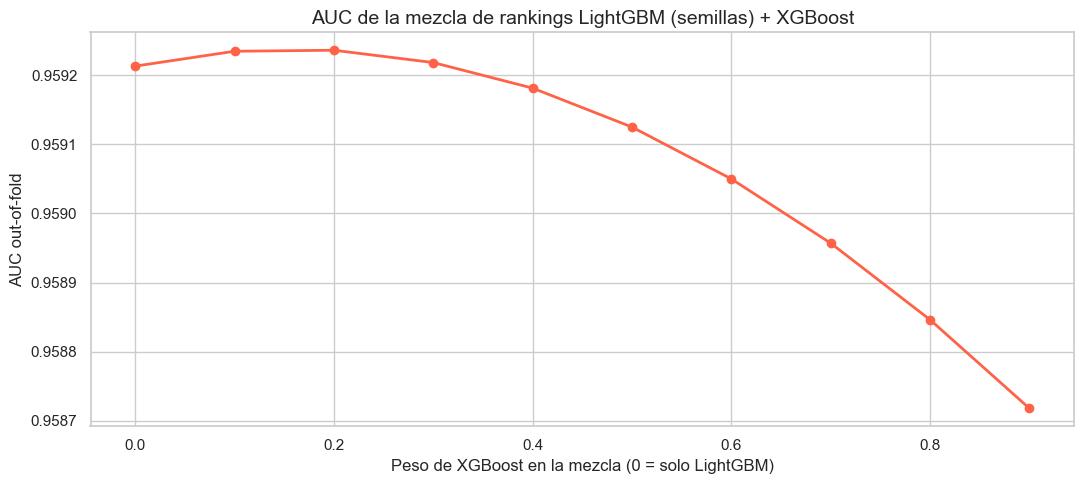

  peso XGBoost 0.0: AUC OOF = 0.95921
  peso XGBoost 0.1: AUC OOF = 0.95923
  peso XGBoost 0.2: AUC OOF = 0.95924
  peso XGBoost 0.3: AUC OOF = 0.95922
  peso XGBoost 0.4: AUC OOF = 0.95918
  peso XGBoost 0.5: AUC OOF = 0.95913
  peso XGBoost 0.6: AUC OOF = 0.95905
  peso XGBoost 0.7: AUC OOF = 0.95896
  peso XGBoost 0.8: AUC OOF = 0.95885
  peso XGBoost 0.9: AUC OOF = 0.95872

Mejor peso de XGBoost: 0.2  ->  AUC OOF 0.95924
  Mezcla vs LightGBM semillas        +0.00002  (desvio 0.00003, gana 4/5, t =  2.00, p = 0.1160)


In [5]:
r_lgb = pd.Series(oof).rank(pct=True).values
r_xgb = pd.Series(oof_xgb).rank(pct=True).values

pesos  = np.round(np.arange(0, 0.91, 0.1), 1)
mezcla = {w: roc_auc_score(y, (1 - w) * r_lgb + w * r_xgb) for w in pesos}

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(list(mezcla), list(mezcla.values()), marker="o", color="tomato", lw=2)
ax.set_xlabel("Peso de XGBoost en la mezcla (0 = solo LightGBM)")
ax.set_ylabel("AUC out-of-fold")
ax.set_title("AUC de la mezcla de rankings LightGBM (semillas) + XGBoost", fontsize=14)
plt.tight_layout()
plt.show()

W_XGB    = max(mezcla, key=mezcla.get)
oof_mix  = (1 - W_XGB) * r_lgb + W_XGB * r_xgb
aucs_mix = aucs_por_fold(oof_mix)

for w, a in mezcla.items():
    print(f"  peso XGBoost {w:.1f}: AUC OOF = {a:.5f}")
print(f"\nMejor peso de XGBoost: {W_XGB}  ->  AUC OOF {mezcla[W_XGB]:.5f}")
pareada(aucs_mix, aucs, "Mezcla vs LightGBM semillas")

## 5. Predicción sobre Test y Submission

In [6]:
mix_test = ((1 - W_XGB) * pd.Series(proba_test).rank(pct=True).values
            + W_XGB * pd.Series(test_xgb).rank(pct=True).values)

np.save("../models/5_lgbm_seeds_oof.npy",  oof)
np.save("../models/5_lgbm_seeds_test.npy", proba_test)

subs = {
    "lgbm_seeds": ("../submissions/5_lgbm_seeds_submission.csv", proba_test, cv_mean),
    "mezcla":     ("../submissions/5_lgbm_seeds_xgb_blend_submission.csv", mix_test, aucs_mix.mean()),
}
for nombre, (ruta, pred, auc) in subs.items():
    pd.DataFrame({"id": test["id"], TARGET: pred}).to_csv(ruta, index=False)
    print(f"{nombre:10s} CV AUC = {auc:.5f}  ->  {ruta}")

ENVIO = "mezcla" if W_XGB > 0 and aucs_mix.mean() > cv_mean else "lgbm_seeds"
FILE, _, CV_ENVIO = subs[ENVIO]
print(f"\nSe envia: {ENVIO}")
print(f"Probabilidad media predicha (LightGBM): {proba_test.mean():.4f}  (tasa base: {y.mean():.4f})")

lgbm_seeds CV AUC = 0.95922  ->  ../submissions/5_lgbm_seeds_submission.csv
mezcla     CV AUC = 0.95924  ->  ../submissions/5_lgbm_seeds_xgb_blend_submission.csv

Se envia: mezcla
Probabilidad media predicha (LightGBM): 0.4436  (tasa base: 0.4436)


In [7]:
# Chequeo de sanidad contra sample_submission (formato e ids)
sample = pd.read_csv("../data/sample_submission.csv")
for ruta, _, _ in subs.values():
    sub = pd.read_csv(ruta)
    assert list(sub.columns) == list(sample.columns), "columnas no coinciden"
    assert len(sub) == len(sample), "cantidad de filas no coincide"
    assert (sub["id"].values == sample["id"].values).all(), "los ids no estan alineados"
    assert sub[TARGET].between(0, 1).all(), "hay probabilidades fuera de [0, 1]"
    assert sub[TARGET].notna().all(), "hay nulos en la prediccion"
print("Chequeos OK - submissions listas para enviar.")

Chequeos OK - submissions listas para enviar.


## 6. Envío a Kaggle vía API

In [8]:
COMPETITION = "playground-series-s6e10"
MSG = (f"LightGBM lr=0.02 x{len(SEMILLAS)} semillas"
       + (f" + XGB rank blend w={W_XGB}" if ENVIO == "mezcla" else "")
       + f" - CV AUC={CV_ENVIO:.5f}")

!kaggle competitions submit -c {COMPETITION} -f "{FILE}" -m "{MSG}"

9 submissions remaining today.
Successfully submitted to Predicting Airline Satisfaction



  0%|          | 0.00/7.80M [00:00<?, ?B/s]
  0%|          | 16.0k/7.80M [00:00<01:31, 89.4kB/s]
  8%|▊         | 656k/7.80M [00:00<00:07, 946kB/s]  
  9%|▉         | 736k/7.80M [00:00<00:08, 845kB/s]
 13%|█▎        | 1.00M/7.80M [00:01<00:06, 1.03MB/s]
 17%|█▋        | 1.34M/7.80M [00:01<00:05, 1.28MB/s]
 32%|███▏      | 2.53M/7.80M [00:01<00:01, 3.29MB/s]
 75%|███████▌  | 5.86M/7.80M [00:01<00:00, 9.72MB/s]
100%|██████████| 7.80M/7.80M [00:02<00:00, 3.82MB/s]


In [9]:
# Score publico de los envios (esperar unos segundos a que Kaggle lo puntue)
!kaggle competitions submissions -c {COMPETITION}

     ref  fileName                               date                        description                                                           status                     publicScore  privateScore  
--------  -------------------------------------  --------------------------  --------------------------------------------------------------------  -------------------------  -----------  ------------  
57579989  5_lgbm_seeds_xgb_blend_submission.csv  2026-10-24 02:45:18.783000  LightGBM lr=0.02 x3 semillas + XGB rank blend w=0.2 - CV AUC=0.95924  SubmissionStatus.PENDING                              
57500494  4_lgbm_xgb_blend_submission.csv        2026-10-21 23:46:35.013000  LightGBM leaves=255 + XGB rank blend w=0.3 - CV AUC=0.95911           SubmissionStatus.COMPLETE  0.95859                    
57370373  3_xgboost_submission.csv               2026-10-18 22:04:16.173000  XGBoost - crudas - cat nativas - CV AUC=0.95858                       SubmissionStatus.COMPLETE  0.95820           

## 7. Conclusiones

_(se completan después de ejecutar)_